In [1]:
import os
import re
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from scipy.stats import linregress
from scipy.spatial.distance import cdist, pdist, squareform
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb, to_hex
from matplotlib.path import Path
from matplotlib.patches import PathPatch
import seaborn as sns
from Bio import SeqIO

In [2]:
sns.set_theme(style="whitegrid", context="notebook")
SERO = range(1, 5)
plt.rcParams['font.family'] = 'sans-serif'
SERO_COLORS = {
    1: "#D55E00",  # DENV1
    2: "#009E73",  # DENV2
    3: "#56B4E9",  # DENV3
    4: "#CC79A7"   # DENV4
}

TYPE_INTENSITY = {
    "COL": 1.0,
    "EXP": 0.45,
    "MAP": 0.75
}

COLOR_UNKNOWN = "#888888"

In [3]:
AA_SEQS_EXP_E="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E.fasta"
AA_SEQS_EXP_E_MAP="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"
META_EXP = "../resources/experimental_data/metadata/E_DENV{}_meta.tsv"
# Asignacion de linaje de las cepas de referencia (Genome Detective).
LIN_EXP = "../resources/experimental_data/genome_detective/Lineages_DENV{}_EXP.csv"

TIME_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_time.nwk"
META_MERGE = "../resources/merged_data/metadata/merged_DENV{}_meta.tsv"

PROYECTION_COORDS = "../output/projected_coordinates_DENV{}.csv"

# Cartografia antigenica (insumo y salida publicada de Katzelnick, Zenodo 5365818)
TITERS_KATZ = "../resources/experimental_data/neutralization-titers.txt"
MAP_2D_PUB  = "../resources/experimental_data/2d-antigenic-map.txt"
MAP_3D_PUB  = "../resources/experimental_data/3d-antigenic-map.txt"
ACMAP_FIT   = "../output/acmap_fitted_{}d.csv"
PRED_TITERS_COL = "../output/predicted_titers_colombia_sub.csv"
ACMAP_COL_PLACED = "../output/acmap_colombia_placed_2d.csv"

DIST_EPITOPE_GRANTHAM = "../output/distances_epitope_grantham_DENV{sero}.csv"
DIST_EPITOPE_GRANTHAM_VAL = "../output/validation_distances_epitope_grantham_DENV{sero}.csv"
DIST_ALL_GRANTHAM_VAL = "../output/validation_distances_all_grantham_DENV{sero}.csv"
DIST_EPITOPE_HAMMING_VAL = "../output/validation_distances_epitope_hamming_DENV{sero}.csv"
DIST_ALL_HAMMING_VAL = "../output/validation_distances_all_hamming_DENV{sero}.csv"

## Cargar Matriz de distancias

### Matrices de distancia Grantaham epitópico

In [4]:
dfs_epi_grantham = []
for sero in SERO:
    filename = DIST_EPITOPE_GRANTHAM.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_grantham.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

df_matrices = dfs_epi_grantham

Matriz de DENV1 cargada desde: ../output/distances_epitope_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/distances_epitope_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/distances_epitope_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/distances_epitope_grantham_DENV4.csv


## Cargar mapa antigénico

In [5]:
mapa_ag = pd.read_csv(
    "../resources/experimental_data/2d-antigenic-map.txt",
    sep=r"\s+",
    header=None,
    names=["type", "strainID", "coord1", "coord2"]
)

# Extraer serotipo: acepta DENV1 y DEN1
mapa_ag["sero_num"] = mapa_ag["strainID"].str.extract(
    r"(?:DENV|DEN)(\d)",
    expand=False
)

mapa_ag["sero"] = "DENV" + mapa_ag["sero_num"]
antigenos = mapa_ag[mapa_ag["type"] == "AG"].copy()
sueros = mapa_ag[mapa_ag["type"] == "SR"].copy()

print(f"Antígenos: {len(antigenos)}")
print(f"Antisueros: {len(sueros)}")

Antígenos: 412
Antisueros: 36


### Figura: mapa antigénico

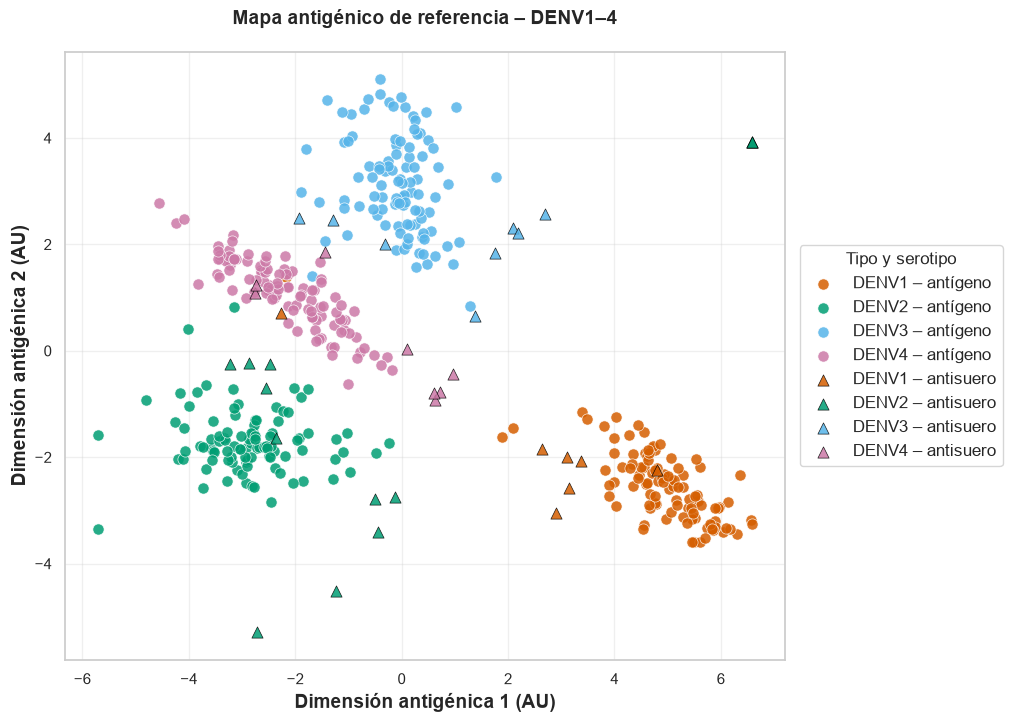

In [6]:
unique_sero = sorted(mapa_ag["sero"].unique())

fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=SERO_COLORS[int(sero.replace("DENV", ""))],
        marker="o",
        s=65,
        alpha=0.85,
        edgecolors="white",
        linewidth=0.5,
        label=f"{sero} – antígeno"
    )


for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]

    ax.scatter(
        df["coord1"],
        df["coord2"],
        color=SERO_COLORS[int(sero.replace("DENV", ""))],
        marker="^",
        s=65,
        alpha=0.85,
        edgecolors="black",
        linewidth=0.5,
        label=f"{sero} – antisuero"
    )


ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "Mapa antigénico de referencia – DENV1–4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.grid(
    True,
    alpha=0.3
)

# Leyenda
ax.legend(
    title="Tipo y serotipo",
    title_fontsize=12,
    fontsize=12,
    frameon=True,
    ncol=1,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)
ax.set_aspect("equal", adjustable="box")
plt.savefig(
    "../figures/mapa_ref.png",
    dpi=300,
    bbox_inches="tight"
)

### Cargar Metadata de las secuencias de referencia

In [119]:
info_viruses = pd.read_csv(
    "../resources/experimental_data/metadata/information.viruses.csv"
)

### Tabla: Caracteristicas secuencias de referencia

In [120]:
# Si antigenos ya tiene genotype, eliminarlo antes del merge
if "genotype" in antigenos.columns:
    antigenos = antigenos.drop(columns=["genotype"])

# Información de genotipo
info_genotype = (
    info_viruses[
        ["unified.sequence.names", "genotype"]
    ]
    .drop_duplicates(subset="unified.sequence.names")
)

# Agregar genotipo
antigenos = antigenos.merge(
    info_genotype,
    left_on="strainID",
    right_on="unified.sequence.names",
    how="left"
)

# Eliminar columna auxiliar
antigenos = antigenos.drop(columns=["unified.sequence.names"])

# País
antigenos["country"] = (
    antigenos["strainID"]
    .str.split("/")
    .str[1]
    .str.strip()
    .str.title()
)

# Distribución de genotipos por serotipo
tabla_genotipos = (
    antigenos
    .groupby(["sero", "genotype"])
    .size()
    .reset_index(name="n")
)

tabla = (
    antigenos
    .groupby(["sero", "genotype"])
    .agg(
        n=("strainID", "size"),
        paises=("country", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

# Ordenar genotipos por frecuencia dentro de cada serotipo
tabla = (
    tabla
    .sort_values(["sero", "n"], ascending=[True, False])
)

print(tabla.to_string(index=False))

 sero             genotype  n                                                       paises
DENV1              DENV1-I 95                         Cambodia, Myanmar, Thailand, Vietnam
DENV1              DENV1-V  8               Bolivia, Peru, Puertorico, Thailand, Venezuela
DENV1             DENV1-II  1                                                     Thailand
DENV1             DENV1-IV  1                                                        Nauru
DENV2        DENV2-Asian I 83                                           Cambodia, Thailand
DENV2 DENV2-Asian/American  7                 Brazil, Guyana, Nicaragua, Thailand, Vietnam
DENV2   DENV2-Cosmopolitan  4                                     India, Thailand, Vietnam
DENV2       DENV2-American  2                                                  Peru, Tonga
DENV2       DENV2-Sylvatic  2                                            Malaysia, Senegal
DENV2       DENV2-Asian II  1                                                    Newguinea

### Figura: Distribución temporal de las secuencias asociadas al mapa antigénico

DENV1: 105 secuencias presentes en el mapa antigénico
DENV2: 86 secuencias presentes en el mapa antigénico
DENV3: 102 secuencias presentes en el mapa antigénico
DENV4: 92 secuencias presentes en el mapa antigénico


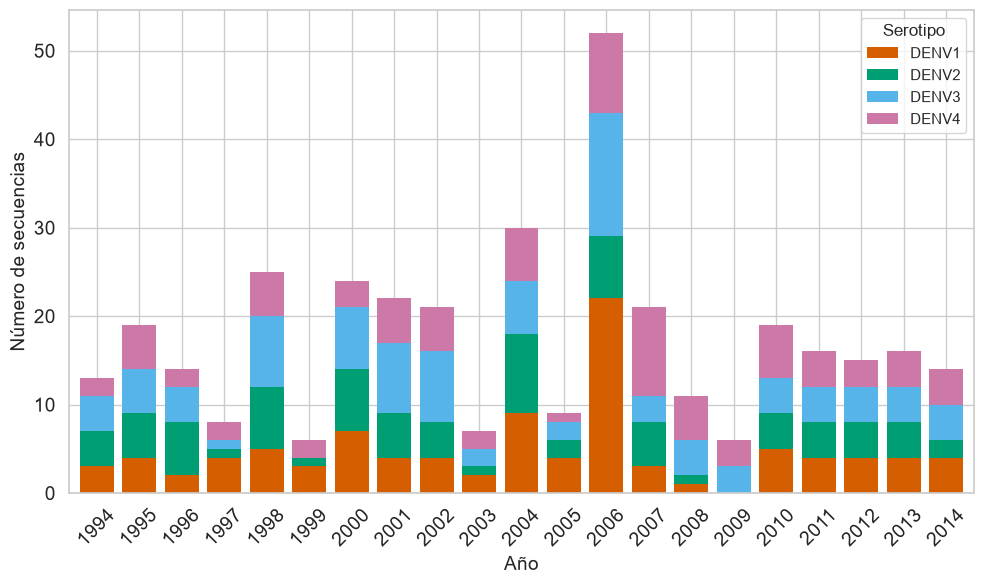

In [121]:
plot_data = []

for sero in range(1, 5):
    
    fasta_file = AA_SEQS_EXP_E_MAP.format(sero)

    records = list(SeqIO.parse(fasta_file, "fasta"))

    valid_ids = {
        record.id.strip()
        for record in records
    }

    print(
        f"DENV{sero}: {len(valid_ids)} secuencias "
        f"presentes en el mapa antigénico"
    )

    df = pd.read_csv(
        META_EXP.format(sero),
        sep="\t"
    )

    df["strain"] = (
        df["strain"]
        .astype(str)
        .str.strip()
    )

    df = df[
        df["strain"].isin(valid_ids)
    ].copy()

    df["date"] = pd.to_datetime(
        df["date"],
        format="mixed",
        errors="coerce"
    )

    df = df.dropna(subset=["date"])

    df["year"] = df["date"].dt.year

    counts = (
        df.groupby("year")
        .size()
        .reindex(
            range(1994, 2015),
            fill_value=0
        )
        .reset_index()
    )

    counts.columns = [
        "year",
        "count"
    ]

    counts["serotype"] = f"DENV{sero}"

    plot_data.append(counts)


plot_df = pd.concat(
    plot_data,
    ignore_index=True
)


plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)

plot_pivot = plot_pivot[
    ["DENV1", "DENV2", "DENV3", "DENV4"]
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)

plot_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[SERO_COLORS[i] for i in range(1, 5)],
    width=0.8,
    linewidth=0
)

ax.set_xlabel(
    "Año",
    fontsize=14
)

ax.set_ylabel(
    "Número de secuencias",
    fontsize=14
)
'''
ax.set_title(
    "Distribución temporal de las secuencias asociadas al mapa antigénico",
    fontsize=14,
    fontweight="bold"
)
'''
ax.legend(
    title="Serotipo"
)

ax.tick_params(
    axis="x",
    rotation=45,
    labelsize=14
)
ax.tick_params(
    axis="y",
    labelsize=14
)

plt.tight_layout()
plt.savefig("../figures/distribucion_temporal_ref.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Figura: heatmap de secuencias colombianas

D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
D:\EQUIPO\Documents HDD\Tesis\denv-cross-inmunity\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


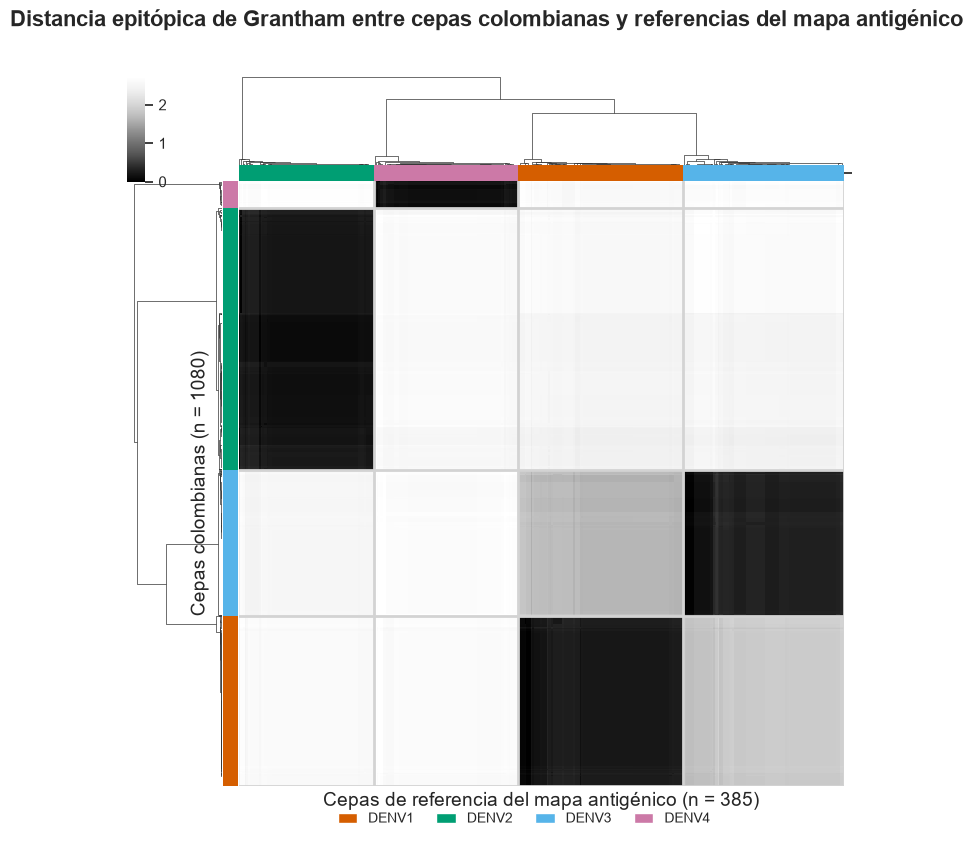

  Filas en bloques puros de serotipo: 100.0% | columnas: 100.0%
  Guardado: clustermap_DENV_all_combined.png


In [122]:
combined_df = pd.concat(df_matrices, axis=0)

row_sero = pd.Series(np.repeat([1, 2, 3, 4], [len(d) for d in df_matrices]),
                     index=combined_df.index)
col_sero = pd.Series([int(re.search(r"(?:DENV|DEN)(\d)", c).group(1))
                      for c in combined_df.columns],
                     index=combined_df.columns)

vmax = float(np.nanpercentile(combined_df.values, 99))

g = sns.clustermap(
    combined_df,
    cmap="Greys_r", vmin=0, vmax=vmax,
    method="average", metric="euclidean",
    row_colors=row_sero.map(SERO_COLORS),
    col_colors=col_sero.map(SERO_COLORS),
    xticklabels=False, yticklabels=False,
    figsize=(7.5, 7.5),
    dendrogram_ratio=(0.13, 0.13),
    colors_ratio=0.022,
    cbar_pos=(0.02, 0.83, 0.025, 0.14),
)

g.ax_heatmap.set_xlabel(
    f"Cepas de referencia del mapa antigénico (n = {combined_df.shape[1]})", fontsize=14)
g.ax_heatmap.set_ylabel("")
g.ax_row_colors.set_ylabel(
    f"Cepas colombianas (n = {combined_df.shape[0]})", fontsize=14, labelpad=10)
g.ax_row_colors.set_xlabel("")
g.ax_col_colors.set_ylabel("")


def bloques(seq, minfrac=0.02):
    """Tramos consecutivos del mismo serotipo que ocupen al menos minfrac."""
    out, ini = [], 0
    for k in range(1, len(seq) + 1):
        if k == len(seq) or seq[k] != seq[ini]:
            if (k - ini) >= minfrac * len(seq):
                out.append((ini, k, seq[ini]))
            ini = k
    return out


r_ord = row_sero.values[g.dendrogram_row.reordered_ind]
c_ord = col_sero.values[g.dendrogram_col.reordered_ind]
ax = g.ax_heatmap

for ini, fin, s in bloques(r_ord):
    ax.axhline(fin, color="lightgrey", lw=2)
for ini, fin, s in bloques(c_ord):
    ax.axvline(fin, color="lightgrey", lw=2)

g.fig.legend(
    handles=[Patch(facecolor=SERO_COLORS[s], label=f"DENV{s}") for s in (1, 2, 3, 4)],
    loc="lower center", bbox_to_anchor=(0.55, -0.045), ncol=4,
    frameon=False, fontsize=10, handlelength=1.4, columnspacing=1.6)

g.fig.suptitle(
    "Distancia epitópica de Grantham entre cepas colombianas y referencias del mapa antigénico",
    y=1.06, fontsize=16, fontweight="bold")

g.savefig("../figures/clustermap_DENV_all_combined.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

pureza_r = sum(f - i for i, f, _ in bloques(r_ord)) / len(r_ord)
pureza_c = sum(f - i for i, f, _ in bloques(c_ord)) / len(c_ord)
print(f"  Filas en bloques puros de serotipo: {pureza_r:.1%} | columnas: {pureza_c:.1%}")
print("  Guardado: clustermap_DENV_all_combined.png")


### Figura: Referencia mas cercana a las secuencias colombianas

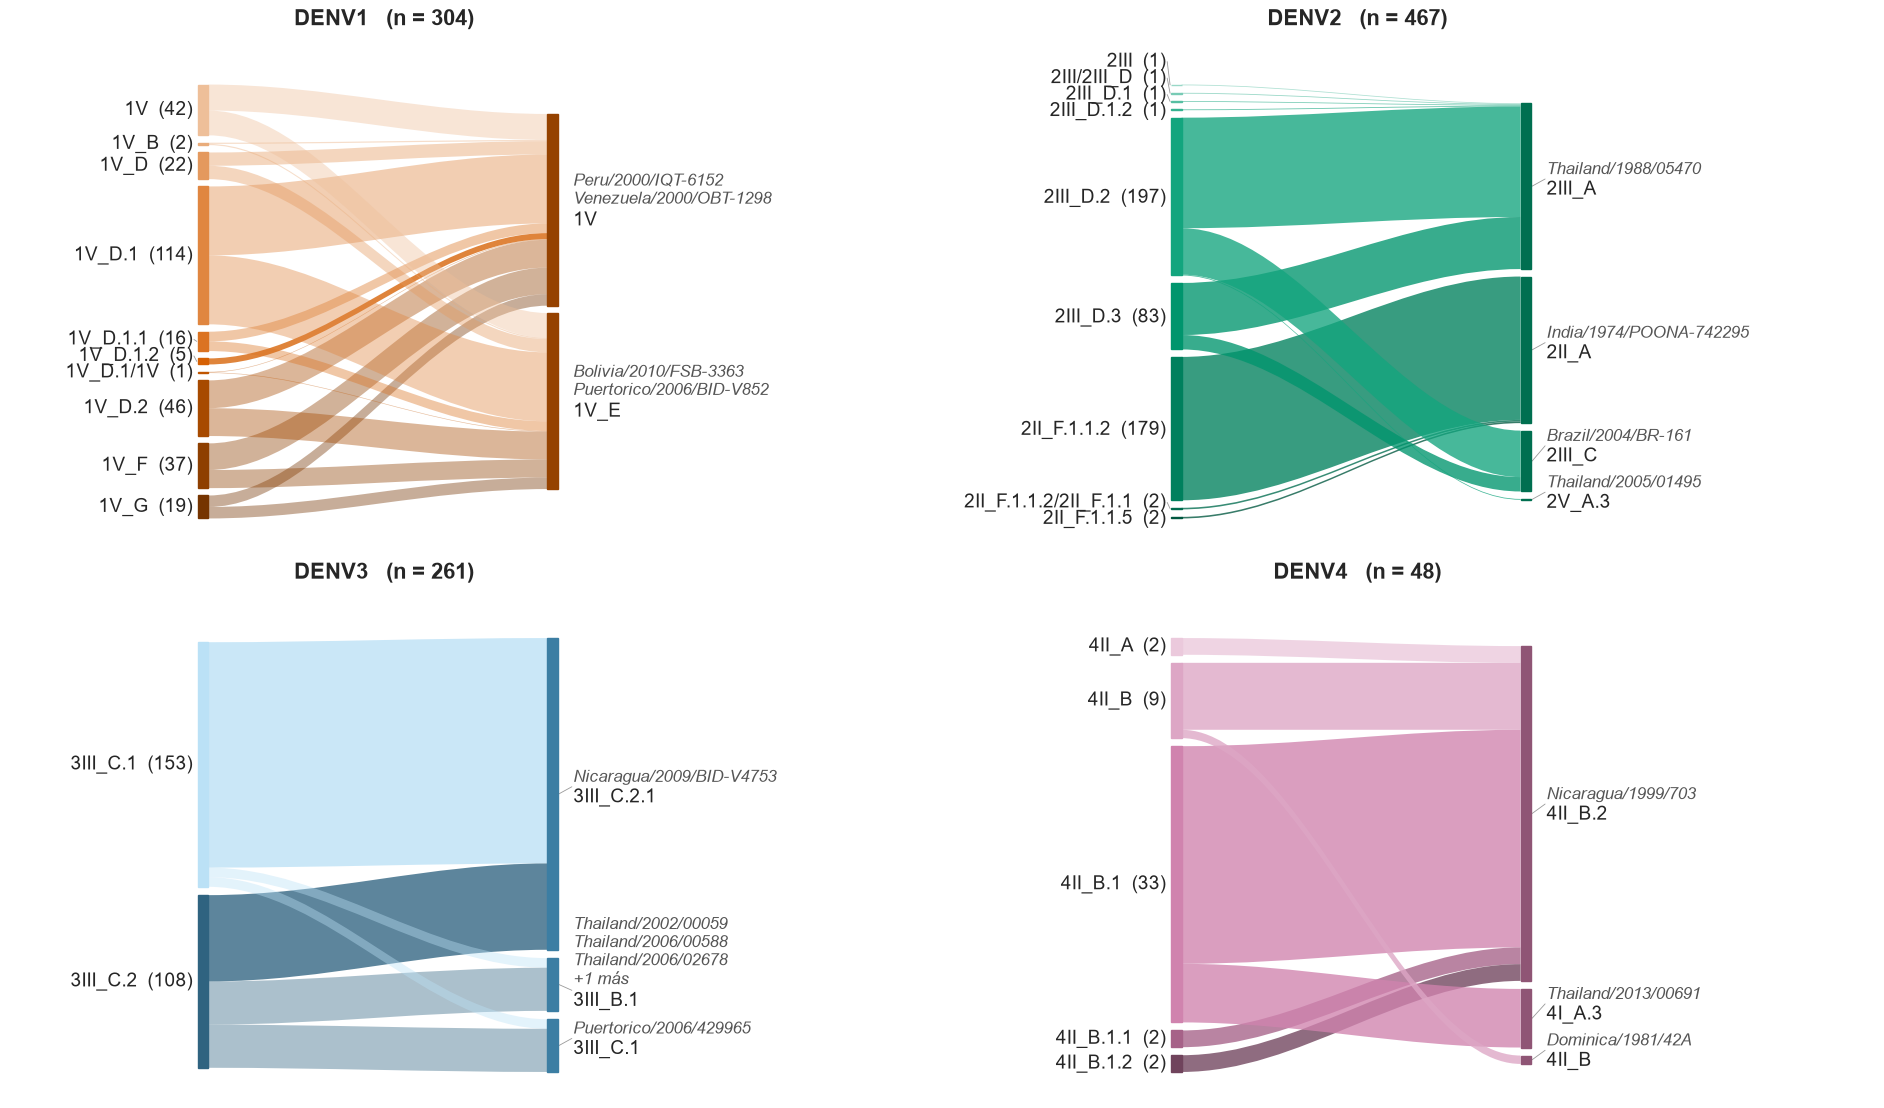

In [13]:
atol = 1e-9

# Alto aproximado de una linea de texto en unidades de los ejes del panel.
LINE = 0.033


def ref_label(ref_id):
    p = ref_id.split("/")
    return f"{p[1].title()}/{p[2]}/{p[3]}"


def country(ref_id):
    return ref_id.split("/")[1].title()


def fmt_dist(vals):
    vals = np.asarray(vals, dtype=float)
    lo, hi = vals.min(), vals.max()
    if np.isclose(lo, hi, atol=atol):
        return f"d = {lo:.3f}"
    return f"d = [{lo:.3f}–{hi:.3f}]"


def shade(hex_color, t):
    """Intensidad sobre el color base del serotipo.
    t < 1 aclara (mezcla con blanco), t = 1 color base, t > 1 oscurece."""
    c = to_rgb(hex_color)
    if t <= 1:
        return to_hex(tuple(1 - t * (1 - v) for v in c))
    return to_hex(tuple(v * (2 - t) for v in c))


def stack(labels, sizes, gap_frac=0.02):
    """Apila los nodos de arriba hacia abajo en unidades de secuencias.
    Devuelve {etiqueta: (base, altura)} y la extension total ocupada."""
    gap = sum(sizes) * gap_frac
    span = sum(sizes) + gap * (len(sizes) - 1)
    pos, top = {}, span
    for lab, s in zip(labels, sizes):
        pos[lab] = (top - s, s)
        top -= s + gap
    return pos, span


def spread(centers, heights, lo=-0.02, hi=1.00):
    """Separa etiquetas que se solapan: empuja cada una lo justo para que
    los bloques no se toquen, manteniendo el orden vertical original.
    Los nodos finos de pocas secuencias quedan asi legibles."""
    n = len(centers)
    if n == 0:
        return []
    y = list(centers)
    order = sorted(range(n), key=lambda i: centers[i])

    for _ in range(4):
        for a, b in zip(order, order[1:]):
            need = (heights[a] + heights[b]) / 2
            if y[b] - y[a] < need:
                y[b] = y[a] + need
        top = y[order[-1]] + heights[order[-1]] / 2
        if top > hi:
            for i in order:
                y[i] -= top - hi
        for a, b in zip(order[::-1], order[::-1][1:]):
            need = (heights[a] + heights[b]) / 2
            if y[a] - y[b] < need:
                y[b] = y[a] - need
        bot = y[order[0]] - heights[order[0]] / 2
        if bot < lo:
            for i in order:
                y[i] += lo - bot

    return y


def leader(ax, x_node, y_node, x_lab, y_lab):
    """Linea guia fina cuando la etiqueta se desplazo respecto a su nodo."""
    if abs(y_lab - y_node) < 0.004:
        return
    ax.plot([x_node, x_lab], [y_node, y_lab],
            color="#999999", lw=0.6, zorder=1, clip_on=False)


def ribbon(ax, x0, y0, x1, y1, h, color, alpha):
    """Cinta de altura constante h entre (x0, y0) y (x1, y1), con los
    bordes como curvas de Bezier. y0 e y1 son los bordes inferiores."""
    xa, xb = x0 + (x1 - x0) * 0.35, x0 + (x1 - x0) * 0.65
    verts = [
        (x0, y0 + h), (xa, y0 + h), (xb, y1 + h), (x1, y1 + h),
        (x1, y1),
        (xb, y1), (xa, y0), (x0, y0),
        (x0, y0 + h),
    ]
    codes = [
        Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.LINETO,
        Path.CURVE4, Path.CURVE4, Path.CURVE4,
        Path.CLOSEPOLY,
    ]
    ax.add_patch(PathPatch(
        Path(verts, codes),
        facecolor=color, edgecolor="none", alpha=alpha, zorder=2
    ))


# ---- 1) Tabla detallada ----
rows = []
for sero, matrix in zip(SERO, df_matrices):
    d = matrix.values.astype(float)
    for i, strain in enumerate(matrix.index):
        if np.isnan(d[i]).all():
            continue
        dmin = np.nanmin(d[i])
        tied_refs = list(matrix.columns[np.isclose(d[i], dmin, atol=atol)])
        rows.append({
            "serotype": sero,
            "seq_col": strain,
            "min_distance": dmin,
            "n_refs_tied": len(tied_refs),
            "n_countries_tied": len({country(r) for r in tied_refs}),
            "countries_tied": ";".join(sorted({country(r) for r in tied_refs})),
            "labels_tied": ";".join(ref_label(r) for r in tied_refs),
            "refs_tied": ";".join(tied_refs),
        })
df_matches = pd.DataFrame(rows)
#df_matches.to_csv("../output/closest_matches_detail.tsv", sep="\t", index=False)


# ---- 2) Figura: flujo linaje colombiano ----

# Linaje de las cepas de referencia segun Genome Detective (columna
# "assignment", p. ej. 1I_K.1.2). Esa herramienta reescribe los nombres
# y les quita las "/", asi que la union se hace sobre el id sin ellas.
ref_lin_map = {}
for s in SERO:
    gd = pd.read_csv(LIN_EXP.format(s))
    ref_lin_map.update(
        zip(gd["name"].astype(str), gd["assignment"].astype(str))
    )


def ref_lineage(ref_id):
    lin = ref_lin_map.get(ref_id.replace("/", ""))
    if lin is None:
        return "?"
    # Genome Detective deja "dengue virus type N" si no asigna linaje.
    if lin.lower().startswith("dengue virus type"):
        return "sin asignar"
    return lin


fig, axes = plt.subplots(2, 2, figsize=(19, 12.5))

for ax, sero in zip(axes.flatten(), SERO):

    base = SERO_COLORS[sero]
    sub = df_matches[df_matches.serotype == sero].copy()

    lin_map = (
        pd.read_csv(META_MERGE.format(sero), sep="\t")
        .set_index("strain")["lineage"]
    )
    sub["lineage"] = lin_map.reindex(sub.seq_col).values
    sub["lineage"] = sub["lineage"].fillna("sin asignar")

    # Linajes en orden alfabetico: para estos nombres coincide con la
    # jerarquia (1V, 1V_B, 1V_D, 1V_D.1 ...), asi la columna queda como un
    # degradado de claro a oscuro y las sublineas quedan juntas.
    lineages = sorted(sub.lineage.unique())
    ramp = (np.linspace(0.40, 1.45, len(lineages))
            if len(lineages) > 1 else [1.0])
    lin_color = {l: shade(base, t) for l, t in zip(lineages, ramp)}
    ref_color = shade(base, 1.30)

    # Un nodo por linaje de referencia. Cuando la referencia mas cercana de
    # una secuencia empata entre cepas de distinto linaje, su peso se
    # reparte por igual entre esos linajes (1/k), de modo que cada panel
    # sigue sumando n secuencias.
    expl = pd.DataFrame(
        [
            (row.lineage, lin, 1 / len(lins), row.refs_tied)
            for row in sub.itertuples()
            for lins in [sorted({ref_lineage(x)
                                 for x in row.refs_tied.split(";")})]
            for lin in lins
        ],
        columns=["lineage", "ref_lin", "w", "refs_tied"],
    )

    grp = (
        expl.groupby("ref_lin")
        .agg(n=("w", "sum"))
        .sort_values("n", ascending=False)
    )
    groups = list(grp.index)

    # Cepas de referencia que pertenecen a cada nodo de linaje.
    refs_of = {
        g: sorted({r for cell in expl.loc[expl.ref_lin == g, "refs_tied"]
                   for r in cell.split(";") if ref_lineage(r) == g})
        for g in groups
    }

    pos_l, span_l = stack(lineages, [float((sub.lineage == l).sum())
                                     for l in lineages])
    pos_r, span_r = stack(groups, [float(grp.loc[g, "n"]) for g in groups])

    # Misma escala en ambos lados para que las cintas no se estrechen
    scale = 1.0 / max(span_l, span_r)
    off_l = (1 - span_l * scale) / 2
    off_r = (1 - span_r * scale) / 2

    # Cintas: se consumen en orden de grupo (izquierda) y de linaje (derecha)
    pairs = expl.groupby(["lineage", "ref_lin"])["w"].sum()
    # Una cinta va opaca solo si todas sus secuencias apuntan a ese linaje
    # sin empate (peso 1); si alguna se reparte, se dibuja translucida.
    pairs_whole = expl.groupby(["lineage", "ref_lin"])["w"].min()
    cur_l = {l: pos_l[l][0] + pos_l[l][1] for l in lineages}
    cur_r = {g: pos_r[g][0] + pos_r[g][1] for g in groups}

    for g in groups:
        for l in lineages:
            w = float(pairs.get((l, g), 0.0))
            if w <= 0:
                continue
            cur_l[l] -= w
            cur_r[g] -= w
            ribbon(
                ax,
                0.03, cur_l[l] * scale + off_l,
                0.97, cur_r[g] * scale + off_r,
                w * scale,
                lin_color[l],
                0.78 if pairs_whole.get((l, g), 1) == 1 else 0.40
            )

    # ---- Nodos y etiquetas: linaje colombiano ----
    yc_l = [(pos_l[l][0] + pos_l[l][1] / 2) * scale + off_l for l in lineages]
    y_lab_l = spread(yc_l, [LINE * 1.15] * len(lineages))

    for l, yc, yl in zip(lineages, yc_l, y_lab_l):
        b, h = pos_l[l]
        ax.add_patch(plt.Rectangle(
            (0.0, b * scale + off_l), 0.03, h * scale,
            color=lin_color[l], zorder=3
        ))
        leader(ax, -0.002, yc, -0.010, yl)
        ax.text(-0.014, yl, f"{l}  ({int(h)})",
                ha="right", va="center", fontsize=14, clip_on=False)

    # ---- Nodos y etiquetas: referencias ----
    yc_r = [(pos_r[g][0] + pos_r[g][1] / 2) * scale + off_r for g in groups]
    shown_r, detail_r = [], []

    for g in groups:
        refs = refs_of[g]
        shown = [ref_label(r) for r in refs[:3]]
        if len(refs) > 3:
            shown.append(f"+{len(refs) - 3} más")
        shown_r.append(shown)

        detail_r.append(g)

    # Cada bloque mide (lineas de cepas + 2 de detalle) lineas de alto
    h_r = [(len(s) + 2) * LINE * 1.08 for s in shown_r]
    y_lab_r = spread(yc_r, h_r)

    for g, yc, yl, shown, detail in zip(groups, yc_r, y_lab_r,
                                        shown_r, detail_r):
        b, h = pos_r[g]
        ax.add_patch(plt.Rectangle(
            (0.97, b * scale + off_r), 0.03, h * scale,
            color=ref_color, zorder=3
        ))
        # Punto de corte entre las cepas (arriba) y el detalle (abajo)
        y_split = yl - (len(shown) - 2) * LINE / 2
        leader(ax, 1.002, yc, 1.038, y_split)
        ax.text(1.042, y_split + 0.1 * LINE, "\n".join(shown),
                ha="left", va="bottom", fontsize=12, 
                color="#555555", style="italic", clip_on=False)
        ax.text(1.042, y_split - 0.1 * LINE, detail,
                ha="left", va="top", fontsize=14, clip_on=False)

    ax.set_title(
        f"DENV{sero}   (n = {len(sub)})",
        fontsize=16,
        fontweight="bold",
        pad=24,
        x=0.42
    )
    ax.set_xlim(-0.52, 1.95)
    ax.set_ylim(-0.06, 1.06)
    ax.set_axis_off()

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig("../figures/closest_experimental_matches.png",
            dpi=300, bbox_inches="tight")
plt.show()

## Proyección secuencias colombianas al mapa antigénico

In [7]:
def project_one(d, ref_xy, scale=None, eps=1e-6):
    d = np.asarray(d, dtype=float)
    ref_xy = np.asarray(ref_xy, dtype=float)

    valid = ~np.isnan(d)
    if valid.sum() < 3:                      # underdetermined: fall back to centroid
        return ref_xy.mean(axis=0)
    d, ref = d[valid], ref_xy[valid]

    w = 1.0 / (d + eps)
    w /= w.mean()                            # mean 1, so tolerances behave
    sw = np.sqrt(w)                          # proper weighting: cost = sum(w * r^2)
    a0 = (w[:, None] * ref).sum(0) / w.sum()

    if scale is None:
        mx = d.max()
        target = d / mx if mx > 0 else d     # assumes ref_xy is on a unit scale
    else:
        target = np.maximum(scale[0] * d + scale[1], 0.0)

    res = lambda a: sw * (np.linalg.norm(ref - a, axis=1) - target)
    sol = least_squares(res, a0, method='lm', max_nfev=100,
                        ftol=1e-8, xtol=1e-8, gtol=1e-8)
    return sol.x if sol.status > 0 else a0

In [8]:
def project_strains(df_matrices, mapa_ag, scales=None, same_sero_only=False):
    """Para cepas que NO están en el mapa (p. ej. las colombianas)."""
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    col_sero = m.reindex(cols)['sero_num'].astype(int).values

    # Aviso si alguna cepa a proyectar ya está entre las referencias (fuga)
    for s in [1, 2, 3, 4]:
        overlap = set(df_matrices[s - 1].index) & set(cols)
        if overlap:
            print(f"DENV{s}: {len(overlap)} cepas también están en las referencias")

    out = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        keep = (col_sero == s) if same_sero_only else np.ones(len(cols), bool)
        sc = scales[s] if scales else None
        xy = np.array([project_one(row[keep], ref_xy[keep], sc) for row in dfm.values])
        out[s] = pd.DataFrame(xy, index=dfm.index, columns=['X', 'Y'])
    return out

In [9]:
projected_coordinates = project_strains(df_matrices, mapa_ag, same_sero_only=True)
[print(f"{key}: {value.head()}") for key, value in projected_coordinates.items()]

for serotype, coords in projected_coordinates.items():
    coords.to_csv(
        PROYECTION_COORDS.format(serotype),
        index=True,
        index_label="Strain"
    )
    print(f"Saved: {PROYECTION_COORDS.format(serotype)}")

1:                                                    X         Y
DenV1/mosquito/Colombia/MAG-CIST-0134/2018  6.361346 -2.805791
DenV1/mosquito/Colombia/MAG-CIST-0151/2018  6.361346 -2.805791
DenV1/un/Colombia/un-UniNorte-1/2001        4.634578 -2.568247
hDenV1/Colombia/ANT-INS-485061/2016         6.361346 -2.805791
hDenV1/Colombia/ANT-UDEA-COA0053/2021       6.361346 -2.805791
2:                                                 X         Y
DenV2/Colombia/VAC-LSPVAC-01056-VI/2024 -2.922646 -1.647507
DenV2/Colombia/VAC-LSPVAC-01460-VI/2024 -3.080213 -1.402809
DenV2/Colombia/VAC-LSPVAC-01585-VI/2024 -3.080213 -1.402809
DenV2/Colombia/VAC-LSPVAC-01723-VI/2024 -3.080213 -1.402809
DenV2/Colombia/VAC-LSPVAC-01759-VI/2024 -2.975551 -1.491833
3:                                             X         Y
hDenV3/Colombia/ANT-UDS-0109587/2012 -1.88789  2.979704
hDenV3/Colombia/ANT-UDS-0221590/2013 -1.88789  2.979704
hDenV3/Colombia/ANT-UDS-0267594/2014 -1.88789  2.979704
hDenV3/Colombia/ANT-UDS-06715

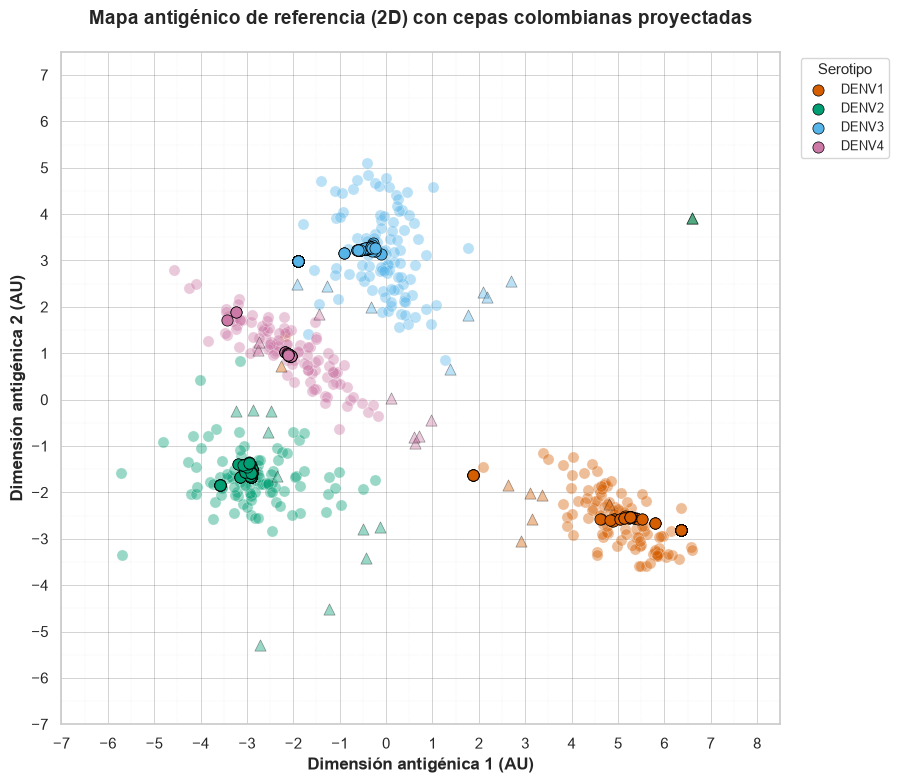

In [26]:
fig, ax = plt.subplots(figsize=(15, 8))
fig.subplots_adjust(
    left=0.10,
    right=0.75,
    bottom=0.12,
    top=0.88
)

# Referencia (Antígenos)
for sero in unique_sero:
    df = antigenos[antigenos["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=SERO_COLORS[int(sero.replace("DENV", ""))],
        marker="o",
        s=65,
        alpha=0.4,
        edgecolors="white",
        linewidth=0.5
    )

# Referencia (Antisueros)
for sero in unique_sero:
    df = sueros[sueros["sero"] == sero]
    ax.scatter(
        df["coord1"], df["coord2"],
        color=SERO_COLORS[int(sero.replace("DENV", ""))],
        marker="^",
        s=65,
        alpha=0.4,
        edgecolors="black",
        linewidth=0.5
    )

# Cepas Colombianas Proyectadas
for sero in [1, 2, 3, 4]:
    sero_str = f"DENV{sero}"
    if sero in projected_coordinates:
        df_proj = projected_coordinates[sero]
        ax.scatter(
            df_proj["X"], df_proj["Y"],
            color=SERO_COLORS[int(sero_str.replace("DENV", ""))],
            marker="o",
            s=65,
            alpha=1,
            edgecolors="black",
            linewidth=0.5,
            label=f"{sero_str}"
        )




all_x = np.concatenate([
    antigenos["coord1"].values,
    sueros["coord1"].values,
    *[projected_coordinates[s]["X"].values for s in projected_coordinates]
])
all_y = np.concatenate([
    antigenos["coord2"].values,
    sueros["coord2"].values,
    *[projected_coordinates[s]["Y"].values for s in projected_coordinates]
])

x_min, x_max = np.floor(all_x.min()) - 1, np.ceil(all_x.max()) + 1
y_min, y_max = np.floor(all_y.min()) - 1, np.ceil(all_y.max()) + 1

ax.set_xticks(np.arange(x_min, x_max + 1, 1))
ax.set_yticks(np.arange(y_min, y_max + 1, 1))

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(
    True,
    which="major",
    linestyle="-",
    linewidth=0.6,
    color="gray",
    alpha=0.4
)

ax.set_xticks(np.arange(x_min, x_max + 1, 0.5), minor=True)
ax.set_yticks(np.arange(y_min, y_max + 1, 0.5), minor=True)
ax.grid(
    True,
    which="minor",
    linestyle=":",
    linewidth=0.3,
    color="gray",
    alpha=0.25
)




ax.set_xlabel(
    "Dimensión antigénica 1 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel(
    "Dimensión antigénica 2 (AU)",
    fontsize=12,
    fontweight="bold"
)
ax.set_title(
    "Mapa antigénico de referencia (2D) con cepas colombianas proyectadas",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.legend(
    title="Serotipo",
    title_fontsize=11,
    fontsize=9,
    frameon=True,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig(
    "../figures/mapa_proy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Validación

## Cargar Matriz de distancias de validación

### Matrices validación de distancia Grantaham epitópico

In [10]:
dfs_epi_grantham_val = []
for sero in SERO:
    filename = DIST_EPITOPE_GRANTHAM_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_grantham_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_epitope_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_epitope_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_epitope_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_epitope_grantham_DENV4.csv


### Matrices validación de distancia Grantaham todo el gen E

In [11]:
dfs_all_grantham_val = []
for sero in SERO:
    filename = DIST_ALL_GRANTHAM_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_all_grantham_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_all_grantham_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_all_grantham_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_all_grantham_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_all_grantham_DENV4.csv


### Matrices validación de distancia Hamming epitópico

In [12]:
dfs_epi_hamming_val = []
for sero in SERO:
    filename = DIST_EPITOPE_HAMMING_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_epi_hamming_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_epitope_hamming_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_epitope_hamming_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_epitope_hamming_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_epitope_hamming_DENV4.csv


### Matrices validación de distancia Hamming todo el gen E

In [13]:
dfs_all_hamming_val = []
for sero in SERO:
    filename = DIST_ALL_HAMMING_VAL.format(sero=sero)
    if not os.path.exists(filename):
        raise FileNotFoundError(f"No existe el archivo para DENV{sero}: {filename}")

    dfs_all_hamming_val.append(pd.read_csv(filename, index_col=0))
    print(f"Matriz de DENV{sero} cargada desde: {filename}")

Matriz de DENV1 cargada desde: ../output/validation_distances_all_hamming_DENV1.csv
Matriz de DENV2 cargada desde: ../output/validation_distances_all_hamming_DENV2.csv
Matriz de DENV3 cargada desde: ../output/validation_distances_all_hamming_DENV3.csv
Matriz de DENV4 cargada desde: ../output/validation_distances_all_hamming_DENV4.csv


## Validación Leave-one-out

In [14]:
def validate_loo(df_matrices, mapa_ag, same_sero_only=False, calibrate=False):
    m = mapa_ag.drop_duplicates(subset='strainID').set_index('strainID')
    cols = df_matrices[0].columns.tolist()
    ref_xy = m.reindex(cols)[['coord1', 'coord2']].values
    sizes = [len(d) for d in df_matrices]
    col_sero = np.repeat([1, 2, 3, 4], sizes)
    if calibrate:
        same_sero_only = True   # la escala se calibra intra-serotipo

    results = {}
    for s in [1, 2, 3, 4]:
        dfm = df_matrices[s - 1]
        ids = dfm.index.tolist()
        D = dfm.values.astype(float)
        in_s = (col_sero == s)

        if calibrate:
            Ds = D[:, in_s]                                  # n x n, mismo serotipo
            assert dfm.columns[in_s].tolist() == ids          # mismo orden filas/columnas
            Dm = cdist(m.loc[ids, ['coord1', 'coord2']].values,
                       m.loc[ids, ['coord1', 'coord2']].values)
            off = ~np.eye(len(ids), dtype=bool) & ~np.isnan(Ds)

        rows = []
        for i, sid in enumerate(ids):
            keep = np.array([c != sid for c in cols])          # quita la propia cepa por ID
            if same_sero_only:
                keep &= in_s
            d, ref = D[i, keep], ref_xy[keep]

            scale = None
            if calibrate:                                      # calibración SIN la cepa evaluada
                pm = off.copy(); pm[i, :] = False; pm[:, i] = False
                scale = np.polyfit(Ds[pm], Dm[pm], 1)

            px, py = project_one(d, ref, scale)

            # líneas base con los mismos candidatos (mismo serotipo, sin la propia)
            same = in_s & np.array([c != sid for c in cols])
            mean_xy = ref_xy[same].mean(axis=0)
            dd = np.where(np.isnan(D[i]), np.inf, D[i]); dd[~same] = np.inf
            nn_xy = ref_xy[np.argmin(dd)]

            rx, ry = m.loc[sid, ['coord1', 'coord2']]
            rows.append(dict(strainID=sid, real_X=rx, real_Y=ry, proj_X=px, proj_Y=py,
                             mean_X=mean_xy[0], mean_Y=mean_xy[1],
                             nn_X=nn_xy[0], nn_Y=nn_xy[1]))
        results[s] = pd.DataFrame(rows).set_index('strainID')
    return results


def resumen(results):
    out = []
    for s, df in results.items():
        def rmse(a, b):
            return np.sqrt(np.mean((df[f'{a}_X'] - df['real_X'])**2 +
                                   (df[f'{a}_Y'] - df['real_Y'])**2))
        r_p, r_m, r_n = rmse('proj', 'x'), rmse('mean', 'x'), rmse('nn', 'x')
        out.append(dict(Serotipo=f'DENV-{s}', n=len(df),
                        r_X=stats.pearsonr(df.real_X, df.proj_X)[0],
                        r_Y=stats.pearsonr(df.real_Y, df.proj_Y)[0],
                        RMSE_proy=r_p, RMSE_media=r_m, RMSE_vecino=r_n,
                        skill_vs_media=1 - r_p / r_m))
    return pd.DataFrame(out).round(4)

In [15]:
# Comparacion LOO de las cuatro metricas de distancia.
# Sin RMSE_vecino: solo proyeccion contra la linea base de la media del serotipo.
METRICAS = {
    "epitopo-Grantham": dfs_epi_grantham_val,
    "genE-Grantham":    dfs_all_grantham_val,
    "epitopo-Hamming":  dfs_epi_hamming_val,
    "genE-Hamming":     dfs_all_hamming_val,
}
VARIANTES = {
    "base":           dict(),
    "intra":          dict(same_sero_only=True),
    "calibrada":      dict(calibrate=True)
}


def _filas(results, metrica, variante):
    out = []
    for s, df in results.items():
        def rmse(a):
            return np.sqrt(np.mean((df[f"{a}_X"] - df["real_X"]) ** 2 +
                                   (df[f"{a}_Y"] - df["real_Y"]) ** 2))

        def r2(eje):
            real, proy = df[f"real_{eje}"], df[f"proj_{eje}"]
            ss_res = ((real - proy) ** 2).sum()
            ss_tot = ((real - real.mean()) ** 2).sum()
            return 1 - ss_res / ss_tot      # negativo = peor que la media del eje

        r_p, r_m = rmse("proj"), rmse("mean")
        out.append(dict(Metrica=metrica, Variante=variante, Serotipo=f"DENV-{s}",
                        n=len(df),
                        r_X=stats.pearsonr(df.real_X, df.proj_X)[0],
                        r_Y=stats.pearsonr(df.real_Y, df.proj_Y)[0],
                        R2_X=r2("X"), R2_Y=r2("Y"),
                        RMSE_proy=r_p, RMSE_media=r_m,
                        skill=1 - r_p / r_m))
    return out


filas = []
for mname, mats in METRICAS.items():
    for vname, kw in VARIANTES.items():
        print(f"LOO: {mname} / {vname}")
        filas.extend(_filas(validate_loo(mats, mapa_ag, **kw), mname, vname))

comparacion = pd.DataFrame(filas).round(4)

# Resumen: mejora sobre la media del serotipo (positivo = la proyeccion aporta)
print("\nskill = 1 - RMSE_proy / RMSE_media\n")
print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                              columns="Metrica", values="skill")
                 .reindex(columns=list(METRICAS)).round(3).to_string())

print("\nRMSE de proyeccion\n")
print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                              columns="Metrica", values="RMSE_proy")
                 .reindex(columns=list(METRICAS)).round(3).to_string())

for eje in ("X", "Y"):
    print(f"\nR2 del eje {eje}\n")
    print(comparacion.pivot_table(index=["Variante", "Serotipo"],
                                  columns="Metrica", values=f"R2_{eje}")
                     .reindex(columns=list(METRICAS)).round(3).to_string())


LOO: epitopo-Grantham / base
LOO: epitopo-Grantham / intra
LOO: epitopo-Grantham / calibrada
LOO: genE-Grantham / base
LOO: genE-Grantham / intra
LOO: genE-Grantham / calibrada
LOO: epitopo-Hamming / base
LOO: epitopo-Hamming / intra
LOO: epitopo-Hamming / calibrada
LOO: genE-Hamming / base
LOO: genE-Hamming / intra
LOO: genE-Hamming / calibrada

skill = 1 - RMSE_proy / RMSE_media

Metrica             epitopo-Grantham  genE-Grantham  epitopo-Hamming  genE-Hamming
Variante  Serotipo                                                                
base      DENV-1               0.029         -0.014            0.020        -0.047
          DENV-2              -0.043         -0.064           -0.052        -0.076
          DENV-3               0.078          0.087            0.084         0.099
          DENV-4               0.020         -0.048            0.018        -0.052
calibrada DENV-1              -0.245         -0.329           -0.249        -0.342
          DENV-2              -0.3

# Analisis de ruido

In [29]:
import glob
from scipy.spatial import procrustes

def read_final(p):
    rows=[l.split() for l in open(p) if l.startswith("AG")]
    return pd.DataFrame({"id":[r[1] for r in rows],"x":[float(r[2]) for r in rows],"y":[float(r[3]) for r in rows]}).set_index("id")

def read_layout(p):
    rows=[l.split() for l in open(p) if l.startswith("AG")]
    return pd.DataFrame({"id":[r[2] for r in rows],"x":[float(r[3]) for r in rows],"y":[float(r[4]) for r in rows]}).set_index("id")

def align(A,B):
    """Rota/refleja/traslada A sobre B (sin escala)."""
    ca,cb=A.mean(0),B.mean(0); A0,B0=A-ca,B-cb
    U,S,Vt=np.linalg.svd(A0.T@B0); R=U@Vt
    return A0@R+cb

final=read_final("../resources/experimental_data/2d-antigenic-map.txt")
ids=final.index
F=final.values
sero=np.array([i.split("/")[0] for i in ids])

devs=[]; aligned=[]
for p in sorted(glob.glob("../resources/experimental_data/predictions/D2/pred-*-layout.txt")):
    L=read_layout(p).reindex(ids)
    assert L.notna().all().all()
    A=align(L.values,F); aligned.append(A)
    devs.append(np.linalg.norm(A-F,axis=1))
aligned=np.array(aligned); devs=np.array(devs)      # (100, 412)
print("mapas:",devs.shape)

# desviación por cepa respecto al mapa final y entre mapas (a la media alineada)
rms_final=np.sqrt((devs**2).mean(0))
M=aligned.mean(0)
rms_mean=np.sqrt(((aligned-M)**2).sum(2).mean(0))

ids_val = pd.read_csv("../output/ids_385_validadas.csv")["strainID"].astype(str)
en_val = ids.isin(ids_val)                       # máscara sobre las 412 cepas del mapa
print("validadas halladas en el mapa:", en_val.sum(), "de", len(ids_val))   # debe dar 385 de 385

res = []
for s in ["DENV1", "DENV2", "DENV3", "DENV4"]:
    m = (sero == s) & en_val                     # <- solo cepas del serotipo con secuencia
    sd_ser = np.sqrt(((F[m] - F[m].mean(0))**2).sum(1).mean())
    res.append(dict(Serotipo=s, n=m.sum(),
        ruido_RMS_vs_final=np.sqrt((devs[:, m]**2).mean()),
        ruido_mediana_cepa=np.median(rms_final[m]),
        ruido_p90_cepa=np.percentile(rms_final[m], 90),
        dispersion_serotipo_RMSE_media=sd_ser))
r = pd.DataFrame(res).round(3); print(r.to_string(index=False))
r["ratio"] = (r.ruido_RMS_vs_final / r.dispersion_serotipo_RMSE_media).round(3)
print(r[["Serotipo", "ratio"]].to_string(index=False))

top = pd.Series(rms_final, index=ids)[en_val].sort_values(ascending=False).head(8)
print(top.round(2))

mapas: (100, 412)
validadas halladas en el mapa: 385 de 385
Serotipo   n  ruido_RMS_vs_final  ruido_mediana_cepa  ruido_p90_cepa  dispersion_serotipo_RMSE_media
   DENV1 105               0.828               0.507           1.086                           1.285
   DENV2  86               0.941               0.640           1.162                           1.072
   DENV3 102               0.858               0.597           1.309                           1.109
   DENV4  92               0.966               0.521           1.614                           1.092
Serotipo  ratio
   DENV1  0.644
   DENV2  0.878
   DENV3  0.774
   DENV4  0.885
id
DENV1/CAMBODIA/2003/FJ639680      4.18
DENV4/THAILAND/2010/00780/10      3.94
DENV2/CAMBODIA/2008/GQ868638      3.51
DENV3/THAILAND/2006/02121/06      3.22
DENV4/THAILAND/2011/00257/11      2.88
DENV1/PUERTORICO/2006/BID-V852    2.61
DENV4/THAILAND/2013/00691/13      2.56
DENV2/THAILAND/2006/00127/06      2.50
dtype: float64


## Figura: distancia antigénica (AU) vs distancia epitópica de Grantham, intra-serotipo

In [ ]:
_ag_ref = (mapa_ag[mapa_ag["type"] == "AG"]
           .drop_duplicates("strainID")
           .set_index("strainID"))
refs = dfs_epi_grantham_val[0].columns.tolist()
assert set(refs) <= set(_ag_ref.index), "hay referencias fuera del mapa antigenico"

# Matriz genetica (385 x 385) y matriz antigenica en AU sobre el mismo orden
G_ref = pd.concat(dfs_epi_grantham_val, axis=0).loc[refs, refs].values.astype(float)
G_ref = (G_ref + G_ref.T) / 2                      # fuerza simetria exacta
A_ref = squareform(pdist(_ag_ref.loc[refs, ["coord1", "coord2"]].values))

sero_ref = np.array([int(r.split("/")[0].replace("DENV", "").replace("DEN", ""))
                     for r in refs])
_iu = np.triu_indices(len(refs), k=1)              # cada par una sola vez
pares = pd.DataFrame({
    "grantham": G_ref[_iu],
    "au":       A_ref[_iu],
    "sero_i":   sero_ref[_iu[0]],
    "sero_j":   sero_ref[_iu[1]],
})
pares_intra = pares[pares["sero_i"] == pares["sero_j"]].copy()
pares_intra["sero"] = pares_intra["sero_i"]


def _corr(d):
    r, p_r = stats.pearsonr(d["grantham"], d["au"])
    rho, p_rho = stats.spearmanr(d["grantham"], d["au"])
    return r, p_r, rho, p_rho

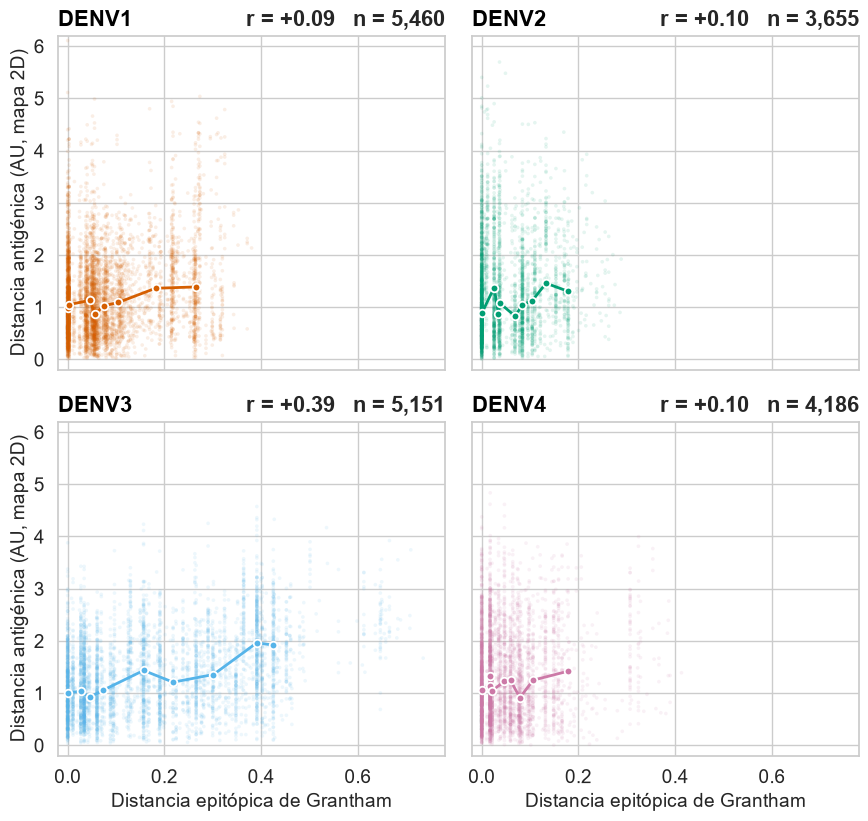

In [38]:
XLIM = (-0.02, 0.78)
YLIM = (-0.2, 6.2)
N_BINS = 8

fig, axes = plt.subplots(2, 2, figsize=(9.0, 8.0),
                         sharex=True, sharey=True)
fig.subplots_adjust(left=0.095, right=0.985, top=0.975, bottom=0.075,
                    wspace=0.07, hspace=0.155)

n_fuera = 0
bins_reales, bins_pos = {}, {}
for ax, s in zip(axes.ravel(), SERO):
    d = pares_intra[pares_intra["sero"] == s]
    col = SERO_COLORS[s]
    n_fuera += int((d["au"] > YLIM[1]).sum())

    ax.scatter(d["grantham"], d["au"], s=7, alpha=0.10,
               color=col, edgecolors="none", rasterized=True)
    _d0 = d[d["grantham"] == 0]
    _dp = d[d["grantham"] > 0]
    _qs = np.unique(np.quantile(_dp["grantham"], np.linspace(0, 1, N_BINS + 1)))
    _b = pd.cut(_dp["grantham"], bins=_qs, include_lowest=True)
    _med = (_dp.groupby(_b, observed=True)
               .agg(x=("grantham", "median"), y=("au", "median"))
               .reset_index(drop=True))
    bins_pos[s] = len(_med)
    if len(_d0):
        _med = pd.concat([pd.DataFrame({"x": [0.0],
                                        "y": [_d0["au"].median()]}),
                          _med], ignore_index=True)
    bins_reales[s] = len(_med)
    ax.plot(_med["x"], _med["y"], "-o", color=col, lw=2, ms=5.5,
            mec="white", mew=1.3, zorder=3)

    r, p, rho, _ = _corr(d)
    ax.set_title(f"DENV{s}", loc="left", fontsize=16, fontweight="bold",
                 color="black", pad=7)
    ax.set_title(f"r = {r:+.2f}   n = {len(d):,}", loc="right",
                 fontsize=16, fontweight="bold", pad=7)

    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.tick_params(labelsize=14)

for ax in axes[1, :]:
    ax.set_xlabel("Distancia epitópica de Grantham", fontsize=14)
for ax in axes[:, 0]:
    ax.set_ylabel("Distancia antigénica (AU, mapa 2D)", fontsize=14)

fig.savefig("../figures/grantham_vs_antigenic_distance.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [33]:
_filas = []
for _etq, _d in ([("Intra-serotipo (global)", pares_intra)] +
                 [(f"  DENV{s}", pares_intra[pares_intra["sero"] == s])
                  for s in SERO]):
    r, p, rho, p_rho = _corr(_d)
    _filas.append({"subconjunto": _etq, "n": len(_d),
                   "Pearson r": round(r, 3),
                   "p (Pearson)": "p < 1e-300" if p == 0 else f"p = {p:.1e}",
                   "Spearman rho": round(rho, 3),
                   "Grantham sd": round(_d["grantham"].std(), 3)})
resumen_grantham_au = pd.DataFrame(_filas)
print(resumen_grantham_au.to_string(index=False))

# Piso de resolucion: pares con epitopos identicos que aun asi difieren en AU
_cero = pares_intra[pares_intra["grantham"] == 0]
print(f"\nPares con Grantham epitópico = 0: {len(_cero):,} "
      f"({100 * len(_cero) / len(pares_intra):.1f} % de los intra)")
print(f"  distancia antigénica de esos pares: "
      f"mediana {_cero['au'].median():.2f} AU, "
      f"p95 {_cero['au'].quantile(0.95):.2f} AU, "
      f"máx {_cero['au'].max():.2f} AU")

            subconjunto     n  Pearson r  p (Pearson)  Spearman rho  Grantham sd
Intra-serotipo (global) 18452      0.179 p = 1.6e-132         0.187        0.118
                  DENV1  5460      0.086  p = 1.7e-10         0.124        0.086
                  DENV2  3655      0.104  p = 3.1e-10         0.145        0.058
                  DENV3  5151      0.388 p = 5.7e-185         0.353        0.161
                  DENV4  4186      0.104  p = 1.6e-11         0.065        0.065

Pares con Grantham epitópico = 0: 4,004 (21.7 % de los intra)
  distancia antigénica de esos pares: mediana 0.96 AU, p95 2.77 AU, máx 9.49 AU


## Figura: comparación de las cuatro métricas de distancia genética

In [24]:
N_BOOT = 400
_rng = np.random.default_rng(0)

_ag_ref = (mapa_ag[mapa_ag["type"] == "AG"]
           .drop_duplicates("strainID")
           .set_index("strainID"))


def _r_ci(g, a, n_boot=N_BOOT):
    """r de Pearson sobre los pares, con IC95 por bootstrap de cepas."""
    n = g.shape[0]
    I, J = np.triu_indices(n, k=1)
    obs = stats.pearsonr(g[I, J], a[I, J])[0]
    bs = np.empty(n_boot)
    for b in range(n_boot):
        k = _rng.integers(0, n, n)                 # remuestrea cepas
        m = k[I] != k[J]                           # descarta auto-pares
        bs[b] = stats.pearsonr(g[np.ix_(k, k)][I[m], J[m]],
                               a[np.ix_(k, k)][I[m], J[m]])[0]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return obs, lo, hi


_filas = []
for _nombre, _dfs in METRICAS.items():
    _refs = _dfs[0].columns.tolist()
    _G = pd.concat(_dfs, axis=0).loc[_refs, _refs].values.astype(float)
    _G = (_G + _G.T) / 2
    _A = squareform(pdist(_ag_ref.loc[_refs, ["coord1", "coord2"]].values))
    _sr = np.array([int(r.split("/")[0].replace("DENV", "").replace("DEN", ""))
                    for r in _refs])
    for s in SERO:
        _i = np.where(_sr == s)[0]
        r, lo, hi = _r_ci(_G[np.ix_(_i, _i)], _A[np.ix_(_i, _i)])
        _filas.append({"metrica": _nombre, "sero": s, "cepas": len(_i),
                       "pares": len(_i) * (len(_i) - 1) // 2,
                       "r": r, "ic_lo": lo, "ic_hi": hi})

comparacion_metricas = pd.DataFrame(_filas)

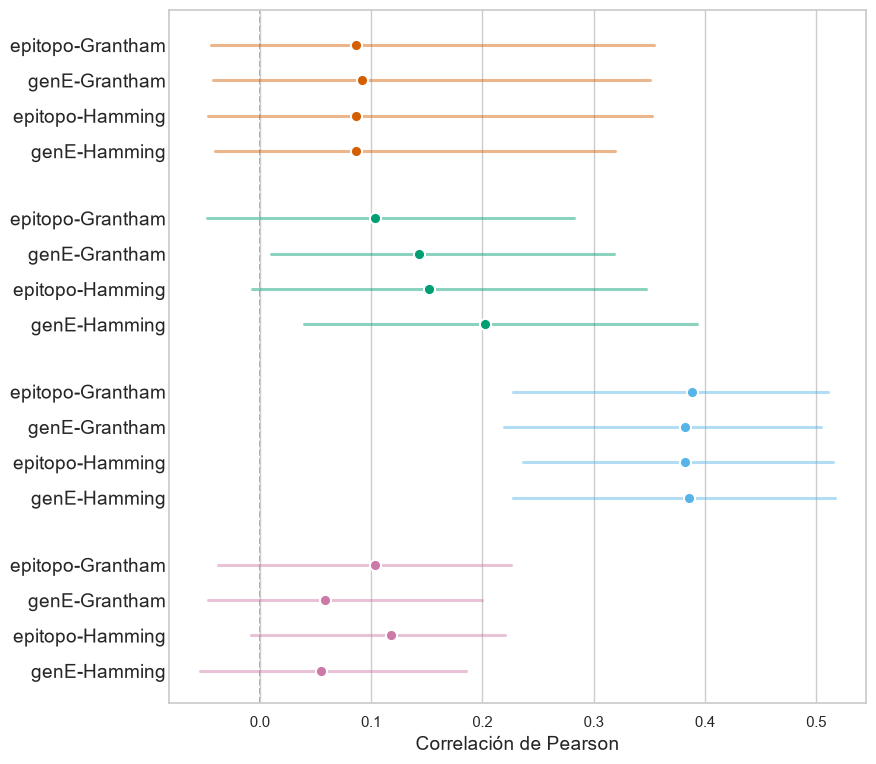

In [42]:
_orden = list(METRICAS)
fig, ax = plt.subplots(figsize=(9, 9))

_y, _ticks, _labels = 0.0, [], []
for s in list(SERO)[::-1]:
    col = SERO_COLORS[s]
    for _nombre in _orden[::-1]:
        _f = comparacion_metricas.query("metrica == @_nombre and sero == @s").iloc[0]
        ax.plot([_f["ic_lo"], _f["ic_hi"]], [_y, _y], "-",
                color=col, lw=2.2, alpha=0.45, solid_capstyle="round")
        ax.plot(_f["r"], _y, "o", color=col, ms=8,
                mec="white", mew=1.4, zorder=3)
        _ticks.append(_y)
        _labels.append(_nombre)
        _y += 1
    _y += 0.9

ax.axvline(0, color="#999999", lw=1.2, ls="--", zorder=0)
ax.set_yticks(_ticks)
ax.set_yticklabels(_labels, fontsize=14)
ax.tick_params(axis="y", length=0, pad=2)
ax.set_ylim(-0.9, _y - 0.9)
ax.set_xlabel("Correlación de Pearson",
              fontsize=14)
ax.grid(axis="y", visible=False)

#fig.suptitle("Correlación entre cuatro métricas de distancia genética y la distancia antigénica, por serotipo.",
#             fontsize=16, fontweight="bold", x=0.022, ha="left", y=0.965)

fig.savefig("../figures/metricas_vs_antigenic_distance.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [23]:
_t = comparacion_metricas.copy()
_t["IC95"] = _t.apply(lambda f: f"[{f['ic_lo']:+.2f}, {f['ic_hi']:+.2f}]", axis=1)
_t["r"] = _t["r"].round(3)
_t["sero"] = "DENV" + _t["sero"].astype(str)
print(_t.pivot(index="metrica", columns="sero", values="r").to_string())
print()
print(_t[["sero", "metrica", "cepas", "pares", "r", "IC95"]].to_string(index=False))

_cruza = comparacion_metricas.query("ic_lo <= 0 <= ic_hi")
print(f"\nCombinaciones cuyo IC95 incluye el 0: {len(_cruza)} de "
      f"{len(comparacion_metricas)}")
print("  " + ", ".join(f"DENV{int(f.sero)}/{f.metrica}"
                       for f in _cruza.itertuples()))

sero              DENV1  DENV2  DENV3  DENV4
metrica                                     
epitopo-Grantham  0.086  0.104  0.388  0.104
epitopo-Hamming   0.087  0.152  0.382  0.118
genE-Grantham     0.091  0.143  0.382  0.059
genE-Hamming      0.087  0.202  0.386  0.055

 sero          metrica  cepas  pares     r           IC95
DENV1 epitopo-Grantham    105   5460 0.086 [-0.04, +0.35]
DENV2 epitopo-Grantham     86   3655 0.104 [-0.05, +0.28]
DENV3 epitopo-Grantham    102   5151 0.388 [+0.23, +0.51]
DENV4 epitopo-Grantham     92   4186 0.104 [-0.04, +0.23]
DENV1    genE-Grantham    105   5460 0.091 [-0.04, +0.35]
DENV2    genE-Grantham     86   3655 0.143 [+0.01, +0.32]
DENV3    genE-Grantham    102   5151 0.382 [+0.22, +0.50]
DENV4    genE-Grantham     92   4186 0.059 [-0.05, +0.20]
DENV1  epitopo-Hamming    105   5460 0.087 [-0.05, +0.35]
DENV2  epitopo-Hamming     86   3655 0.152 [-0.01, +0.35]
DENV3  epitopo-Hamming    102   5151 0.382 [+0.24, +0.52]
DENV4  epitopo-Hamming     92   4

## Figura: distancia antigenica proyectada al linaje anteriormente dominante

La misma figura que hay en DistancesCalculation.ipynb con la distancia
epitopica de Grantham, recalculada sobre la distancia euclidiana entre las
coordenadas proyectadas en el mapa antigenico.


DENV1: matriz proyectada (304, 304) | 26 coordenadas distintas
DENV2: matriz proyectada (467, 467) | 69 coordenadas distintas
DENV3: matriz proyectada (261, 261) | 30 coordenadas distintas
DENV4: matriz proyectada (48, 48) | 13 coordenadas distintas


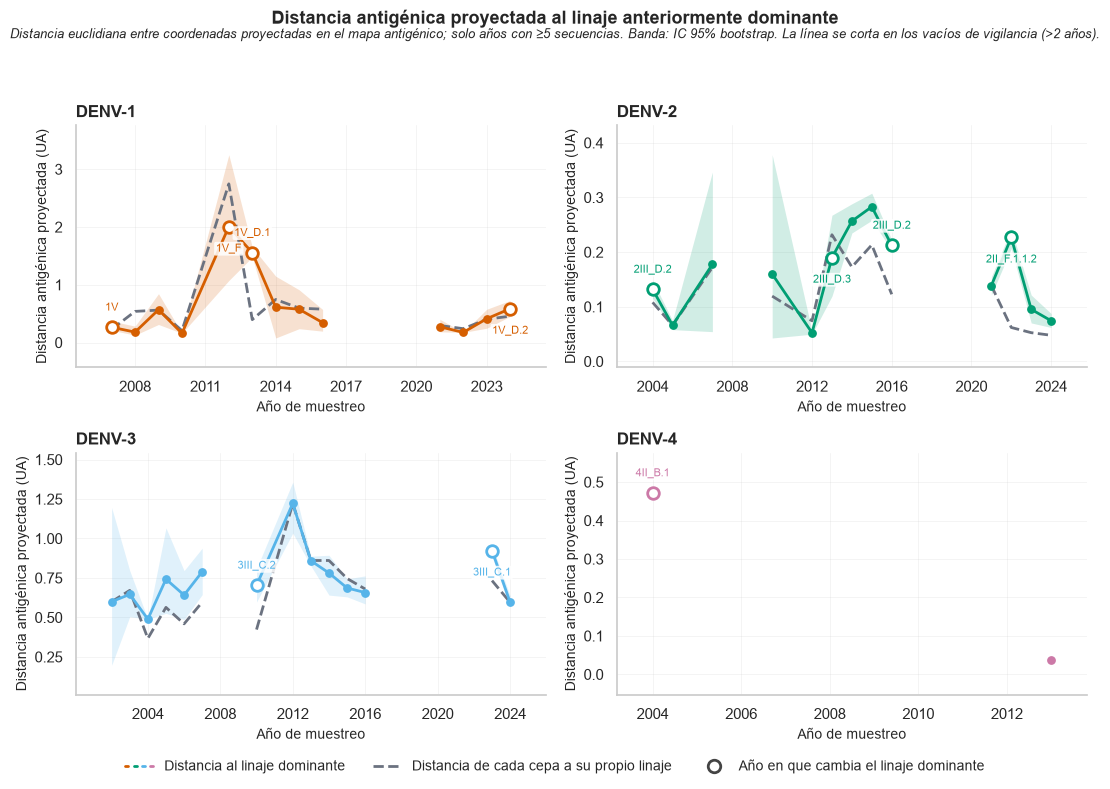


DENV1
 year  n lin_prev    dom  cambio  media  propio  frac_cero
 2007 13     1V_G     1V    True  0.265   0.229        0.0
 2008 15       1V     1V   False  0.181   0.539        0.0
 2009  7       1V     1V   False  0.568   0.562        0.0
 2010  9       1V     1V   False  0.160   0.207        0.0
 2012 14       1V   1V_F    True  2.007   2.746        0.0
 2013 87     1V_F 1V_D.1    True  1.556   0.396        0.0
 2014  5   1V_D.1 1V_D.1   False  0.612   0.745        0.0
 2015  9   1V_D.1 1V_D.1   False  0.576   0.596        0.0
 2016 17   1V_D.1 1V_D.1   False  0.345   0.578        0.0
 2021 19   1V_D.1 1V_D.1   False  0.273   0.295        0.0
 2022  7   1V_D.1 1V_D.1   False  0.175   0.240        0.0
 2023 21   1V_D.1 1V_D.1   False  0.412   0.403        0.0
 2024 37   1V_D.1 1V_D.2    True  0.586   0.456        0.0

DENV2
 year   n    lin_prev         dom  cambio  media  propio  frac_cero
 2004   5    2III_D.3    2III_D.2    True  0.132   0.108        0.0
 2005  19    2III_D.2   

In [6]:
# Distancia media de las cepas de cada año al linaje que dominaba el año
# anterior, igual que la figura de DistancesCalculation.ipynb pero midiendo
# sobre el mapa antigénico: distancia euclidiana entre coordenadas proyectadas
# en lugar de distancia epitópica de Grantham.
#
# La celda es autónoma: si projected_coordinates no está en memoria, lee los
# CSV que escribe la celda de proyección.

import matplotlib
import matplotlib.ticker
import matplotlib.legend_handler

# Los metadatos salen de merged_metadata y NO de merged_data: en ese segundo
# las columnas country, genotype y lineage están desalineadas para las
# secuencias no colombianas.
META_MERGED = "merged_metadata/meta_merged_{sero}.tsv"
MIN_N = 5                 # años con menos secuencias que esto no entran
C_SELF = "#6B7280"
N_BOOT_LIN = 2000

try:
    coords_proy = {s: projected_coordinates[s][["X", "Y"]] for s in SERO}
except NameError:
    coords_proy = {s: pd.read_csv(PROYECTION_COORDS.format(s),
                                  index_col=0)[["X", "Y"]] for s in SERO}

# ---- metadatos y matriz de distancias proyectadas, colombiana x colombiana
info_p, dist_p = {}, {}
for sero in SERO:
    xy = coords_proy[sero].dropna()
    meta = pd.read_csv(META_MERGED.format(sero=sero), sep="\t",
                       dtype=str).set_index("strain")
    comunes = [s for s in xy.index if s in meta.index]
    if len(comunes) < len(xy):
        print(f"DENV{sero}: {len(xy) - len(comunes)} cepas proyectadas sin "
              f"metadatos, se omiten")
    xy = xy.loc[comunes]

    df = meta.loc[comunes, ["date", "lineage"]].copy()
    df["year"] = pd.to_numeric(df["date"].str.slice(0, 4), errors="coerce")
    info_p[sero] = df

    M = squareform(pdist(xy.to_numpy(dtype=float)))      # distancia en el mapa
    dist_p[sero] = pd.DataFrame(M, index=comunes, columns=comunes)
    print(f"DENV{sero}: matriz proyectada {M.shape} | "
          f"{len({tuple(np.round(v, 6)) for v in xy.to_numpy()})} coordenadas distintas")


def serie_linaje_proy(sero):
    """Por año: distancia media de las cepas de ese año al linaje que dominaba
    el año anterior, y al propio linaje como línea base. Misma lógica que
    serie_linaje de DistancesCalculation, con la matriz proyectada."""
    df, D = info_p[sero], dist_p[sero]
    cuenta = df.groupby("year").size()
    anios = sorted(y for y in cuenta.index if cuenta[y] >= MIN_N)
    if len(anios) < 2:
        return pd.DataFrame()
    dom = {y: df[df.year == y]["lineage"].mode().iloc[0] for y in anios}

    filas = []
    for k, y in enumerate(anios[1:], start=1):
        L = dom[anios[k - 1]]
        ref = df[(df.lineage == L) & (df.year < y)].index
        cur = df[df.year == y].index
        if len(ref) == 0 or len(cur) == 0:
            continue
        d_prev = D.loc[cur, ref].mean(axis=1).to_numpy()

        d_self = []
        for c in cur:
            own = df[(df.lineage == df.loc[c, "lineage"]) & (df.year < y)].index
            own = own.drop(c, errors="ignore")
            d_self.append(D.loc[c, own].mean() if len(own) else np.nan)
        d_self = np.asarray(d_self, dtype=float)

        bs = np.random.default_rng(0).choice(
            d_prev, (N_BOOT_LIN, len(d_prev))).mean(axis=1)
        filas.append(dict(year=int(y), n=len(cur), lin_prev=L, dom=dom[y],
                          cambio=dom[y] != L, media=d_prev.mean(),
                          lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                          propio=np.nanmean(d_self) if np.isfinite(d_self).any() else np.nan,
                          frac_cero=float((d_prev < 1e-9).mean())))
    return pd.DataFrame(filas)


fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
series_linaje_proy = {}

for ax, sero in zip(axes.ravel(), [1, 2, 3, 4]):
    C_PREV = SERO_COLORS[sero]
    t = series_linaje_proy[sero] = serie_linaje_proy(sero)
    if t.empty:
        ax.set_axis_off()
        continue

    # la línea se corta en los vacíos de vigilancia
    for _, tr in t.groupby(t.year.diff().gt(2).cumsum()):
        ax.fill_between(tr.year, tr.lo, tr.hi, color=C_PREV, alpha=0.18, lw=0)
        ax.plot(tr.year, tr.media, "-", color=C_PREV, lw=2, zorder=3)
        ax.plot(tr.year, tr.propio, "--", color=C_SELF, lw=2, zorder=2)

    camb = t[t.cambio]
    ax.scatter(camb.year, camb.media, s=70, facecolor="white",
               edgecolor=C_PREV, lw=2, zorder=4)
    ax.scatter(t[~t.cambio].year, t[~t.cambio].media, s=28, color=C_PREV, zorder=4)
    for k, (_, r) in enumerate(camb.iterrows()):
        ax.annotate(r["dom"], (r.year, r.media), textcoords="offset points",
                    xytext=(0, 12 if k % 2 == 0 else -18), ha="center",
                    fontsize=8, color=C_PREV, annotation_clip=False, zorder=6,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

    ax.set_title(f"DENV-{sero}", fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("Año de muestreo", fontsize=10)
    ax.set_ylabel("Distancia antigénica proyectada (UA)", fontsize=10)
    ax.grid(alpha=0.25, lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True, nbins=7))
    ax.margins(x=0.09, y=0.16)

h = [tuple(plt.Line2D([], [], color=SERO_COLORS[s], lw=2) for s in (1, 2, 3, 4)),
     plt.Line2D([], [], color=C_SELF, lw=2, ls="--"),
     plt.Line2D([], [], marker="o", ls="", mfc="white", mec="#444444", mew=2, ms=9)]
fig.legend(handles=h,
           labels=["Distancia al linaje dominante",
                   "Distancia de cada cepa a su propio linaje",
                   "Año en que cambia el linaje dominante"],
           handler_map={tuple: matplotlib.legend_handler.HandlerTuple(ndivide=None, pad=0.4)},
           loc="lower center", ncol=3, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, -0.035))

fig.suptitle("Distancia antigénica proyectada al linaje anteriormente dominante",
             fontsize=13, fontweight="bold", y=1.0)
fig.text(0.5, 0.962,
         f"Distancia euclidiana entre coordenadas proyectadas en el mapa antigénico; "
         f"solo años con ≥{MIN_N} secuencias. "
         "Banda: IC 95% bootstrap. La línea se corta en los vacíos de vigilancia (>2 años).",
         ha="center", fontsize=9, style="italic")
fig.tight_layout(rect=[0, 0, 1, 0.945])
fig.savefig("../figures/distancia_linaje_previo_proyectada.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close()

for sero, t in series_linaje_proy.items():
    if t.empty:
        continue
    print(f"\nDENV{sero}")
    print(t[["year", "n", "lin_prev", "dom", "cambio", "media", "propio",
             "frac_cero"]].round(3).to_string(index=False))
print("\n  Guardado: distancia_linaje_previo_proyectada.png")
